In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
## TRACKER FOR GRADIENT EVALUATIONS
def tracker(mode):
  global num_evals
  if mode == 's':
    num_evals = 0
  elif mode == 'i':
    num_evals += 1
  elif mode == 'r':
    return num_evals
  else:
    print(f"Unknown mode: {mode}")

In [3]:
## FUNCTION AND GRADIENT
def f(x):
  # Check size
  assert x.shape == (2, 1)
  # Create X and Y
  X = x[0,0]
  Y = x[1,0]
  output = 0.26*(X**2+Y**2) - 0.48*X*Y
  output = output.view(1,1)
  assert output.shape == (1,1)
  return output

# Compute the gradient
def grad_f(x):

  # Check that this is true (we set this before the for loop)
  assert x.requires_grad == True
  y = f(x)
  # Make sure output is as scalar
  assert y.shape == (1,1)
  grad_term = torch.autograd.grad(outputs=y, inputs=x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

  # Save space (and get rid of any weird extra stuff)
  y = y.detach()
  x = x.detach()
  #grad_term = grad_term.detach()


  # Make sure the gradient is the same sizeas the input
  assert grad_term.shape == x.shape

  # Return
  tracker('i')
  return grad_term

In [4]:
from functools import total_ordering
# GRADIENT DESCENT
def gradient_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term).detach())

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    x = x - step_size * grad_fx

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, x: %.3e, fx: %.3e, grad_norm: %.3e' % (i, x[0], fx.item(), grad_norm.item()))

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [5]:
## RK4

def runge_kutta_4(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_(True)

    x_hist.append(x.detach())
    f_hist.append(f(x).detach())
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)
    grad_norm_hist.append(grad_norm.detach())

    total_iters = 0

    for i in range(max_iters):
        # Runge-Kutta 4 integration of dx/dt = -∇f(x)
        k1 = -grad_f(x)
        k2 = -grad_f(x + 0.5 * step_size * k1)
        k3 = -grad_f(x + 0.5 * step_size * k2)
        k4 = -grad_f(x + step_size * k3)

        dx = (step_size / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        x = x + dx.detach().clone().requires_grad_(True)

        fx = f(x)
        grad_fx = grad_f(x)
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.detach())
        f_hist.append(fx.detach())
        grad_norm_hist.append(grad_norm.detach())

        print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

        total_iters += 1

        if grad_norm <= tol:
            print("converge!")
            break
    return x.detach(), f_hist, grad_norm_hist, x_hist, total_iters

In [6]:
## AB3
def Adams_Bashforth3(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  # want a histogram of the gradients since we can't calculate the gradient
  # with previous x since it was detached
  grad_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  # append the first grad_fx
  grad_hist.append(grad_fx)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term))

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    # Do euler's to get the first step (only one x)
    if i == 0:
      x = x - step_size * grad_hist[i]
    # Now do AB2 (only two x)
    elif i == 1:
      x = x - step_size * (3/2*grad_hist[i]  - 1/2 * grad_hist[i-1])
    # Finally, we can do AB3 (there are enough x's now)
    else:
      x = x - step_size * (23/12*grad_hist[i]  - 16/12 * grad_hist[i-1] + 5/12 * grad_hist[i-2])

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)
    grad_hist.append(grad_fx)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [7]:
## AB3
def Adams_Bashforth3(f, grad_f, step_size, x0, tol=1e-3, max_iters=1000):

  # Save x at each iteration for plotting
  x_hist = []
  # Save f at each iteration for plotting
  f_hist = []
  # Save gradient norm at each iteration for plotting
  # This one is pretty important since we want it to go to zero
  grad_norm_hist = []
  # want a histogram of the gradients since we can't calculate the gradient
  # with previous x since it was detached
  grad_hist = []
  x = x0

  # Set x.requires_grad = True
  x.requires_grad = True

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  # append the first grad_fx
  grad_hist.append(grad_fx)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term).detach())

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    # Do euler's to get the first step (only one x)
    if i == 0:
      x = x - step_size * grad_hist[i]
    # Now do AB2 (only two x)
    elif i == 1:
      x = x - step_size * (3/2*grad_hist[i]  - 1/2 * grad_hist[i-1])
    # Finally, we can do AB3 (there are enough x's now)
    else:
      x = x - step_size * (23/12*grad_hist[i]  - 16/12 * grad_hist[i-1] + 5/12 * grad_hist[i-2])

    # evaluate
    grad_fx = grad_f(x)
    fx = f(x)
    grad_hist.append(grad_fx)

    # For plotting
    grad_norm = torch.norm(grad_fx)

    # Store values
    x_hist.append(x.detach())
    f_hist.append(fx.detach())
    grad_norm_hist.append(grad_norm.detach())

    # Print Values
    print('i: %d, fx: %.3e, grad_norm: %.3e' % (i, fx.item(), grad_norm.item()))

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [8]:
## BACKWARD EULER
def backward_euler_descent(f, grad_f, step_size, x0, tol=1e-3, max_iters=100, inner_iters=10):
    x_hist = []
    f_hist = []
    grad_norm_hist = []

    x = x0.clone().detach().requires_grad_(True)

    # Initial eval
    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)

    x_hist.append(x.clone().detach())
    f_hist.append(fx.item())
    grad_norm_hist.append(grad_norm.item())
    total_iters = 0

    for i in range(max_iters):
        # Fixed-point iteration to solve x = x_k - α ∇f(x)
        x_new = x.clone().detach().requires_grad_(True)
        for _ in range(inner_iters):
            grad = grad_f(x_new)
            x_new = (x - step_size * grad).detach().requires_grad_(True)

        x = x_new.clone().detach().requires_grad_(True)
        fx = f(x)
        grad_fx = grad_f(x)
        grad_norm = torch.norm(grad_fx)

        x_hist.append(x.clone().detach())
        f_hist.append(fx.item())
        grad_norm_hist.append(grad_norm.item())

        print(f'i: {i}, fx: {fx.item():.3e}, grad_norm: {grad_norm.item():.3e}')

        total_iters += 1

        if grad_norm <= tol:
            print('converged!')
            break

    return x, f_hist, grad_norm_hist, x_hist, total_iters

In [9]:
## AM3

def adamsMoulton (f, grad_f, step_size, x0, tol=1e-3, max_iters=1000, inner_iters = 100, inner_tol = 1e-1):

  x_hist = []
  f_hist = []
  grad_hist = []

  # Save gradient norm at each iteration for plotting
  grad_norm_hist = []
  x = x0

  x = x.detach().clone().requires_grad_(True)

  # Add our initial guess to the histogram data for plotting
  x_hist.append(x0)
  f_hist.append(f(x0))
  grad_fx = grad_f(x0)
  grad_norm_term = torch.norm(grad_fx)
  grad_norm_hist.append(torch.norm(grad_norm_term).detach())

  total_iters = 0

  for i in range(max_iters):
    # Gradient descent update
    if i==0:
      grad_fx = grad_f(x)
      grad_hist.append(grad_fx.detach())
      x = x - step_size * grad_fx
    elif i == 1:
        grad_fx = grad_f(x)                      # ✅ Add this
        grad_hist.append(grad_fx.detach())       # ✅ So grad_hist[1] is defined

        x_new = x.clone().detach().requires_grad_(True)
        for j in range(inner_iters):
            grad = grad_f(x_new)
            x_new = (x - step_size * (1/12)* ((5 * grad + 8 * grad_hist[i] - grad_hist[i - 1]))).detach().requires_grad_(True)
            res = torch.norm(x - x_new)
            print(f"{j}: Residual: {res}")
            if res < inner_tol:
                print("Inner Converged!")
                break
        x = x_new.clone().detach().requires_grad_(True)
        grad_fx = grad_f(x)
        grad_hist.append(grad_fx.detach())
    else:
        x_candidate = x.clone().detach().requires_grad_(True)
        for j in range(inner_iters):
            x_next = x - (step_size / 24) * (
                9 * grad_f(x_candidate) +
                19 * grad_hist[i] -
                5 * grad_hist[i - 1] +
                grad_hist[i - 2]
            )
            residual = torch.norm(x_candidate - x_next).item()
            print(f'    inner_iter: {j}, residual: {residual:.3e}')
            if residual < inner_tol:
                break
            x_candidate = x_next.clone().detach().requires_grad_(True)
        x = x_next.clone().detach().requires_grad_(True)
        grad_fx = grad_f(x)
        grad_hist.append(grad_fx.detach())  # ✅ Update grad history



    fx = f(x)
    grad_fx = grad_f(x)
    grad_norm = torch.norm(grad_fx)

    x_hist.append(x.clone().detach())
    f_hist.append(fx.item())
    grad_norm_hist.append(grad_norm.item())

    print(f'i: {i}, fx: {fx.item():.3e}, grad_norm: {grad_norm.item():.3e}')

    total_iters += 1

    # Check stopping criterion
    if grad_norm <= tol:
      print("converge!")
      break

  # optimal x
  x_opt = x.detach()

  return x_opt, f_hist, grad_norm_hist, x_hist, total_iters

In [10]:
## EVALUATIONS

dim = 2
step_size = 1e-1
max_iters = 2000
tol = 1e-4

# random x
x0 = torch.randn(dim,1)

In [22]:
GDSum = 0
RKSum = 0
ABSum = 0
BESum = 0
AMSum = 0

GDSum2 = 0
RKSum2 = 0
ABSum2 = 0
BESum2 = 0
AMSum2 = 0

for _ in range(5):
  # random x
  x0 = 3*torch.randn(dim,1)

  step_size = 1.8
  tracker('s')
  x_opt_gd, f_hist_gd, grad_norm_hist_gd, x_hist_gd, total_iters = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  GDSum2 += total_iters
  GDSum += tracker('r')
  tracker('s')
  step_size = 0.7
  x_opt_rk4, f_hist_rk4, grad_norm_hist_rk4, x_hist_rk4, total_iters = runge_kutta_4(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  RKSum += tracker('r')
  RKSum2 += total_iters
  tracker('s')
  step_size = 0.5
  x_opt_ab, f_hist_ab, grad_norm_hist_ab, x_hist_ab, total_iters = Adams_Bashforth3(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  ABSum += tracker('r')
  ABSum2 += total_iters
  step_size = 0.75
  tracker('s')
  x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be, total_iters = backward_euler_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
  BESum += tracker('r')
  BESum2 += total_iters
  step_size = 1.3
  tracker('s')
  x_opt_am, f_hist_am, grad_norm_hist_am, x_hist_am, total_iters = adamsMoulton(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters, inner_iters=10)
  AMSum += tracker('r')
  AMSum2 += total_iters

print(f"AVG Grad Evals for GD: {GDSum/5} AVG Steps for GD: {GDSum2/5}")
print(f"AVG Grad Evals for RK4: {RKSum/5} AVG Steps for RK4: {RKSum2/5}")
print(f"AVG Grad Evals for AB3: {ABSum/5} AVG Steps for AB3: {ABSum2/5}")
print(f"AVG Grad Evals for BE: {BESum/5} AVG Steps for BE: {BESum2/5}")
print(f"AVG Grad Evals for AM3: {AMSum/5} AVG Steps for AM3: {AMSum2/5}")

Streaming output truncated to the last 5000 lines.
i: 207, fx: 7.386e-01, grad_norm: 2.431e-01
i: 208, fx: 6.984e-01, grad_norm: 2.364e-01
i: 209, fx: 6.603e-01, grad_norm: 2.298e-01
i: 210, fx: 6.244e-01, grad_norm: 2.235e-01
i: 211, fx: 5.904e-01, grad_norm: 2.173e-01
i: 212, fx: 5.582e-01, grad_norm: 2.113e-01
i: 213, fx: 5.278e-01, grad_norm: 2.055e-01
i: 214, fx: 4.991e-01, grad_norm: 1.998e-01
i: 215, fx: 4.719e-01, grad_norm: 1.943e-01
i: 216, fx: 4.462e-01, grad_norm: 1.889e-01
i: 217, fx: 4.219e-01, grad_norm: 1.837e-01
i: 218, fx: 3.989e-01, grad_norm: 1.786e-01
i: 219, fx: 3.772e-01, grad_norm: 1.737e-01
i: 220, fx: 3.566e-01, grad_norm: 1.689e-01
i: 221, fx: 3.372e-01, grad_norm: 1.642e-01
i: 222, fx: 3.189e-01, grad_norm: 1.597e-01
i: 223, fx: 3.015e-01, grad_norm: 1.553e-01
i: 224, fx: 2.851e-01, grad_norm: 1.510e-01
i: 225, fx: 2.695e-01, grad_norm: 1.468e-01
i: 226, fx: 2.549e-01, grad_norm: 1.428e-01
i: 227, fx: 2.410e-01, grad_norm: 1.388e-01
i: 228, fx: 2.279e-01, gr

KeyboardInterrupt: 

In [12]:
step_size = 1e-2
max_iters = int(1e5)
# GD
tracker('s')
x_opt_t, f_hist_t, grad_norm_hist_t, x_hist_t, total_iters = gradient_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
print(f"Number of gradient evaluations for GD: {tracker('r')}")

Streaming output truncated to the last 5000 lines.
i: 15182, x: 1.305e-02, fx: 6.812e-06, grad_norm: 7.382e-04
i: 15183, x: 1.304e-02, fx: 6.807e-06, grad_norm: 7.379e-04
i: 15184, x: 1.304e-02, fx: 6.801e-06, grad_norm: 7.376e-04
i: 15185, x: 1.303e-02, fx: 6.796e-06, grad_norm: 7.373e-04
i: 15186, x: 1.303e-02, fx: 6.791e-06, grad_norm: 7.371e-04
i: 15187, x: 1.302e-02, fx: 6.785e-06, grad_norm: 7.368e-04
i: 15188, x: 1.302e-02, fx: 6.780e-06, grad_norm: 7.365e-04
i: 15189, x: 1.301e-02, fx: 6.774e-06, grad_norm: 7.362e-04
i: 15190, x: 1.301e-02, fx: 6.769e-06, grad_norm: 7.359e-04
i: 15191, x: 1.300e-02, fx: 6.763e-06, grad_norm: 7.356e-04
i: 15192, x: 1.300e-02, fx: 6.758e-06, grad_norm: 7.353e-04
i: 15193, x: 1.299e-02, fx: 6.753e-06, grad_norm: 7.350e-04
i: 15194, x: 1.299e-02, fx: 6.747e-06, grad_norm: 7.347e-04
i: 15195, x: 1.298e-02, fx: 6.742e-06, grad_norm: 7.344e-04
i: 15196, x: 1.298e-02, fx: 6.736e-06, grad_norm: 7.341e-04
i: 15197, x: 1.297e-02, fx: 6.731e-06, grad_norm:

In [13]:
# step_size = 0.7

# # RK4
# tracker('s')
# x_opt_rk4, f_hist_rk4, grad_norm_hist_rk4, x_hist_rk4 = runge_kutta_4(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for RK4: {tracker('r')}")


In [14]:
# step_size = 0.5
# # AB3
# tracker('s')
# x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be = Adams_Bashforth3(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for AB3: {tracker('r')}")

In [15]:
# step_size = 0.75

# # Backward Euler
# tracker('s')
# x_opt_be, f_hist_be, grad_norm_hist_be, x_hist_be = backward_euler_descent(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for backward euler: {tracker('r')}")


In [16]:
# step_size = 1.3  # best num of eval so far: 2682 w/ step size 0.175

# # AM3
# tracker('s')
# x_opt_am, f_hist_am, grad_norm_hist_am, x_hist_am, total_iters = adamsMoulton(f, grad_f, step_size, x0, tol=tol, max_iters=max_iters)
# print(f"Number of gradient evaluations for AM3: {tracker('r')}")

In [17]:
# plot solution paths
# create 2D grid from -5 to 5

# define range and number of pts
xx = torch.linspace(-10,10,200)
yy = torch.linspace(-10,10,200)

# creat grid
X, Y = torch.meshgrid(xx, yy, indexing = 'xy') # 'xy' ensures correct indexing for 2D grid

Z = torch.zeros(X.shape)
for i in range(200):
  for j in range(200):
    input_vec = torch.tensor([X[i,j], Y[i,j]]).view(2,1)
    # put in function
    Z[i,j] = f(input_vec)[0].item()

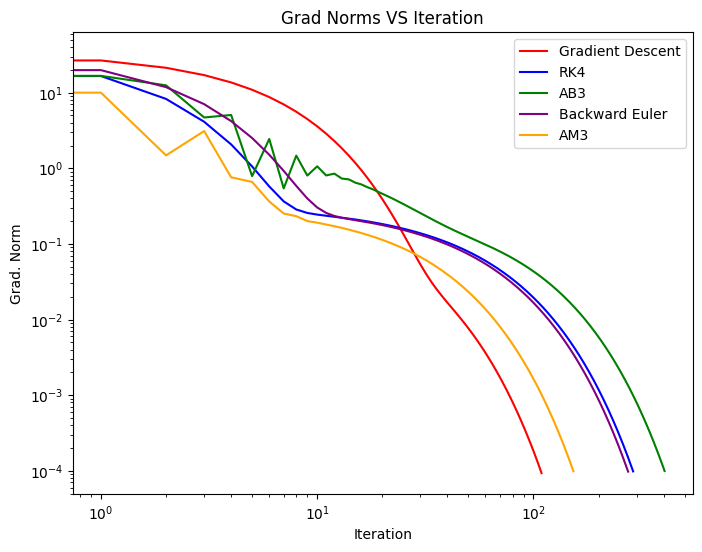

In [18]:
# GD
# plot grad norm vs itr
plt.figure(figsize=(8,6))
plt.loglog(grad_norm_hist_gd, color = "red", label="Gradient Descent")
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('log')
# plt.title("GD: Grad. Norm vs. Iteration")

# RK4
# plot grad norm vs itr
plt.plot(grad_norm_hist_rk4, color="blue", label = 'RK4' )
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('log')

# # AB3
# # plot grad norm vs itr
plt.plot(grad_norm_hist_ab, color="green", label ="AB3")
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('log')

# Back-Euler
# plot grad norm vs itr
plt.plot(grad_norm_hist_be, color='purple', label = "Backward Euler")
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('log')
# AM3
# plot grad norm vs itr
plt.plot(grad_norm_hist_am, color = 'orange', label= 'AM3')
plt.xlabel("Iteration")
plt.ylabel("Grad. Norm")
plt.yscale('log')
plt.title("Grad Norms VS Iteration")
plt.legend()
plt.show()

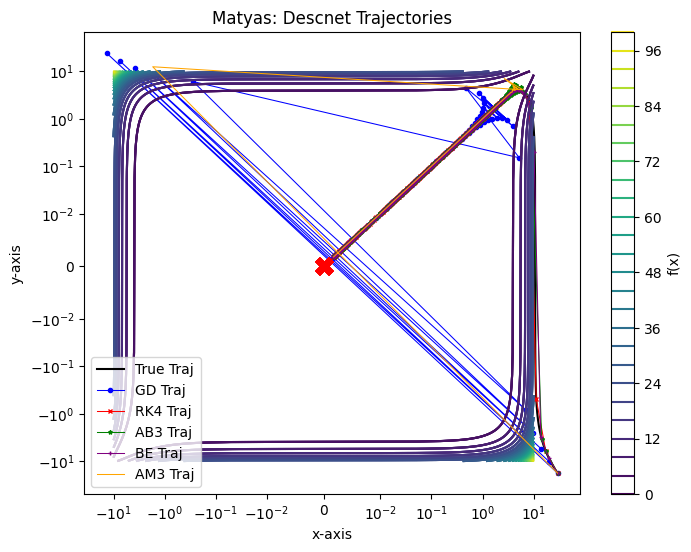

In [19]:
# GD
# plot gradient trajectory
plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_t] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_t] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='', color='black', label='True Traj', markersize = 3, linewidth = 1.5)

x_coords = [x[0].item() for x in x_hist_gd] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_gd] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='o', color='blue', label='GD Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

plt.colorbar(label='f(x)')
plt.title('GD Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# RK4
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_rk4] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_rk4] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='x', color='red', label='RK4 Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('RK4 Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# # AB3
# # plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
# plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_ab] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_ab] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='*', color='green', label='AB3 Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('AB3 Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# Back-Euler
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_be] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_be] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='+', color='purple', label='BE Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('B-E Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.savefig("brent.trjectory.png")  # Save the plot
# plt.show()


# AM3
# plot gradient trajectory
# plt.figure(figsize=(8,6))
# plots the landscape
plt.contour(X, Y, Z, levels=30, cmap='viridis')

x_coords = [x[0].item() for x in x_hist_am] # extract x-coordinates
y_coords = [x[1].item() for x in x_hist_am] # extract y-coordinates

# plot GD trajectory
plt.plot(x_coords, y_coords, marker='', color='orange', label='AM3 Traj', markersize = 3, linewidth = 0.75)
# plot minimizer
plt.plot(0,0, marker='x', color='red', markersize=10, markeredgewidth=5)

# plt.colorbar(label='f(x)')
plt.title('Matyas: Descnet Trajectories')
plt.xlabel('x-axis')
plt.ylabel('y-axis')
plt.xscale('symlog', linthresh=1e-2)
plt.yscale('symlog', linthresh=1e-2)
plt.legend()
plt.savefig("brent.trjectory.png")  # Save the plot
plt.show()